**CLUSTERING :**

CLUSTERING IS OF 2 TYPES :
1) AGGLOMERATIVE CLUSTERING (BOTTOM TO TOP APPROACH)
2) DIVISION CLUSTERING (TOP TO BOTTOM APPROACH)

NOW WE TAKE AN EXAMPLE OF DATASET AND MAKE RUN IT USING THE AGGLOMERATIVE AND DIVISN ALGORITHM:

In [1]:

#LIBRARIES AND DATASET

import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
labels = ['a', 'b', 'c', 'd', 'e']
D = np.array([
    [0, 9, 3, 6, 11],
    [9, 0, 7, 5, 10],
    [3, 7, 0, 9, 2],
    [6, 5, 9, 0, 8],
    [11, 10, 2, 8, 0]
])
print("Distance Matrix:")
print(D)


Distance Matrix:
[[ 0  9  3  6 11]
 [ 9  0  7  5 10]
 [ 3  7  0  9  2]
 [ 6  5  9  0  8]
 [11 10  2  8  0]]


NOW USE **"AGGLOMERATIVE CLUSTERING "** ( BOTTOM TO TOP APPROACH)

Agglomerative Clustering:
Step 1 Merge: 2 4 Distance: 2.0
Step 2 Merge: 1 3 Distance: 5.0
Step 3 Merge: 0 5 Distance: 7.0
Step 4 Merge: 6 7 Distance: 8.166666666666666


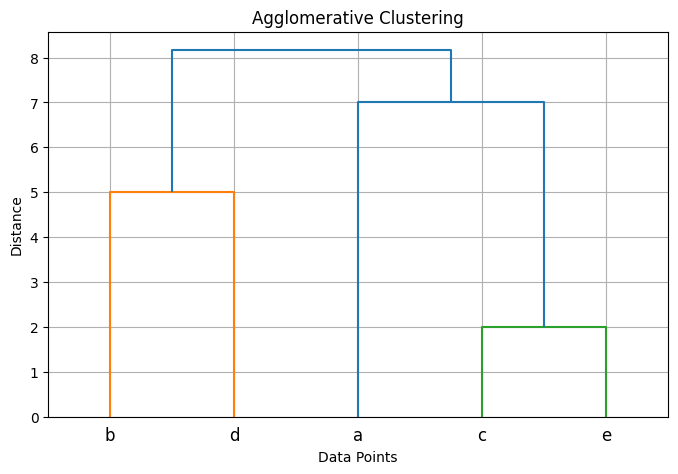

In [2]:

condensed = squareform(D)
Z = linkage(condensed, method='average')
print("Agglomerative Clustering:")
for i, row in enumerate(Z):
    print("Step", i+1, "Merge:", int(row[0]),
          int(row[1]), "Distance:", row[2])
plt.figure(figsize=(8, 5))
dendrogram(Z, labels=labels)
plt.title("Agglomerative Clustering")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.grid()
plt.show()


In [3]:

#THIS PART IS USED TO DIVIDE THE DATA POINTS INTO TWO FINAL CLUSTERS

clusters = fcluster(Z, t=2, criterion='maxclust')
print("Agglomerative Clusters:")
for point, cluster in zip(labels, clusters):
    print(point, "-> Cluster", cluster)


Agglomerative Clusters:
a -> Cluster 2
b -> Cluster 1
c -> Cluster 2
d -> Cluster 1
e -> Cluster 2


NOW WE USE **"DIVISION CLUSTERING"** (TOP TO BOTTOM APPROACH):

In [4]:

def diana_split(cluster):
    remaining = list(cluster)
    avg_dist = {
        i: np.mean([D[i, j] for j in remaining if i != j])
        for i in remaining
    }
    splinter = [max(avg_dist, key=avg_dist.get)]
    remaining.remove(splinter[0])
    while len(remaining) > 1:
        differences = {}
        for i in remaining:
            d_s = np.mean([D[i, j] for j in splinter])
            others = [j for j in remaining if j != i]
            d_r = np.mean([D[i, j] for j in others])
            differences[i] = d_r - d_s
        candidate = max(differences, key=differences.get)
        if differences[candidate] <= 0:
            break
        splinter.append(candidate)
        remaining.remove(candidate)
    return sorted(splinter), sorted(remaining)
split_steps = []
def build_tree(cluster):
    height = max(
        [D[i, j] for i in cluster for j in cluster if i != j],
        default=0
    )
    node = {
        'cluster': cluster,
        'height': height
    }
    if len(cluster) > 1:
        left, right = diana_split(cluster)
        split_steps.append((left, right))
        print(
            "Split:",
            [labels[i] for i in cluster],
            "->",
            [labels[i] for i in left],
            "and",
            [labels[i] for i in right]
        )
        node['left'] = build_tree(left)
        node['right'] = build_tree(right)
    return node
print("Divisive Clustering:")
tree = build_tree(list(range(len(labels))))


Divisive Clustering:
Split: ['a', 'b', 'c', 'd', 'e'] -> ['b', 'd'] and ['a', 'c', 'e']
Split: ['b', 'd'] -> ['b'] and ['d']
Split: ['a', 'c', 'e'] -> ['a'] and ['c', 'e']
Split: ['c', 'e'] -> ['c'] and ['e']


FOR THE PURPOSE OF **"DENDOGRAM DIAGRAM"** GRAPH WE USE THOS CODE TO VISUALIZE THE DIVISION OF CLUSTERING USING  A DENDOGRAM

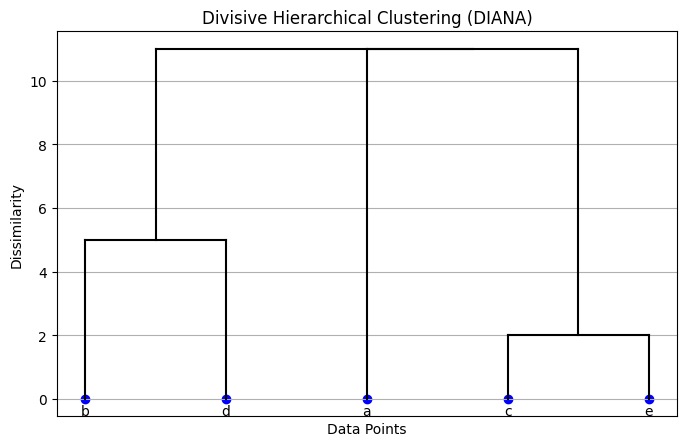

In [5]:

fig, ax = plt.subplots(figsize=(8, 5))
counter = [0]
def draw_tree(node):
    if 'left' not in node:
        x = counter[0]
        counter[0] += 1
        ax.scatter(x, 0, color='blue')
        ax.text(x, -0.5, labels[node['cluster'][0]],
                ha='center')
        return x
    x1 = draw_tree(node['left'])
    x2 = draw_tree(node['right'])
    y = node['height']
    ax.plot([x1, x1],
            [node['left']['height'], y], 'k-')
    ax.plot([x2, x2],
            [node['right']['height'], y], 'k-')
    ax.plot([x1, x2], [y, y], 'k-')
    return (x1 + x2) / 2
draw_tree(tree)
ax.set_title("Divisive Hierarchical Clustering (DIANA)")
ax.set_xlabel("Data Points")
ax.set_ylabel("Dissimilarity")
ax.set_xticks([])
ax.grid(axis='y')
plt.show()
